# LogiTrack: Supply Chain & Logistics Performance Analytics
## Notebook 01: Business Understanding, Data Quality, Cleaning & SQL Storage
**Covers methodology Steps 1 to 6:** business problem → dataset & ER diagram → load raw data → data-quality analysis → cleaning & preprocessing → store cleaned data in SQL (PK/FK constraints).

*Author: Adrish Manna · HCL GUVI Data Science (DSGA-C-WE-E-B15)*

## Step 1: Understand the Business Problem
A logistics company moves shipments from **warehouses** using **drivers**, **vehicles** and **routes**. Each shipment produces a **delivery** outcome and usually a customer **feedback** record. Management cannot see from raw data alone how well the network performs.

| Stakeholder | What they need |
|---|---|
| Operations team | Delay hot-spots (routes, warehouses, time periods), driver workload, vehicle utilisation |
| Management | KPIs: success rate, average delay, customer rating, and where to invest (training, fleet, routes) |
| Customers | On-time delivery and a good service experience |

**Business objectives:** efficiency (fewer and shorter delays), customer satisfaction (rating ≥ 4.0 target), and cost (better use of fleet and capacity).

**Key business questions**
1. What is the overall delivery success rate?
2. Which routes have the most delays?
3. How does driver experience affect delivery performance?
4. Which vehicle types are most efficient?
5. What factors influence customer satisfaction?
6. Are there seasonal patterns in delivery delays?
7. Which warehouses have the best performance?

## Step 2: Understand the Dataset & ER Diagram
7 related tables (official GUVI `logitrack_*_expanded.csv` files, saved in `data/raw/` with the names from the recommended directory structure).

```
 warehouses (PK warehouse_id) ─┐
 drivers    (PK driver_id)    ─┤
 vehicles   (PK vehicle_id)   ─┼──< shipments (PK shipment_id, FK warehouse_id, driver_id, vehicle_id, route_id)
 routes     (PK route_id)     ─┘            │ 1:1
                                     deliveries (PK delivery_id, FK shipment_id)
                                            │ 1:1
                                     feedback   (PK feedback_id, FK delivery_id)
```

**Data dictionary**

| Table | Column | Type | Key | Description |
|---|---|---|---|---|
| warehouses | warehouse_id | INT | PK | Unique warehouse identifier |
| | name / city / state | VARCHAR | | Warehouse name and location |
| | capacity | INT | | Storage capacity (units) |
| drivers | driver_id | INT | PK | Unique driver identifier |
| | name | VARCHAR | | Driver name |
| | experience | INT | | Years of experience |
| | rating | FLOAT | | Average driver rating (1-5) |
| | join_date | DATE | | Joining date |
| vehicles | vehicle_id | INT | PK | Unique vehicle identifier |
| | vehicle_type | VARCHAR | | Truck, Van, Bike |
| | capacity_kg | INT | | Load capacity (kg) |
| | fuel_type | VARCHAR | | Diesel, Petrol, Electric |
| | status | VARCHAR | | Active, Maintenance, Retired |
| routes | route_id | INT | PK | Unique route identifier |
| | origin_city / dest_city | VARCHAR | | Start and end city |
| | distance_km | FLOAT | | Route distance |
| | route_type | VARCHAR | | Express, Standard, Economy |
| shipments | shipment_id | INT | PK | Unique shipment identifier |
| | warehouse_id / driver_id / vehicle_id / route_id | INT | FK | Origin warehouse, assigned driver, vehicle, route |
| | shipment_dt | DATETIME | | Shipment date/time |
| | weight_kg | FLOAT | | Shipment weight |
| | priority | VARCHAR | | High, Medium, Low |
| deliveries | delivery_id | INT | PK | Unique delivery identifier |
| | shipment_id | INT | FK | Related shipment |
| | actual_dt | DATETIME | | Actual delivery time |
| | status | VARCHAR | | Delivered, Delayed, In-Transit, Cancelled |
| | delay_hours | FLOAT | | Hours delayed (0 if on time) |
| feedback | feedback_id | INT | PK | Unique feedback identifier |
| | delivery_id | INT | FK | Related delivery |
| | rating | INT | | Customer rating (1-5) |
| | comment | TEXT | | Customer comment |
| | feedback_dt | DATE | | Feedback date |

In [1]:
# --- Setup: make the project root importable and load shared helpers -------------
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Image

from src import utils
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", palette="Set2")
%matplotlib inline
from src import data_cleaning as dc

## Step 3: Load the Raw Data
All seven CSVs are loaded with Pandas. Then we check shape, columns and data types.

In [2]:
raw = {t: utils.read_raw(t) for t in utils.TABLES}
for t, df in raw.items():
    print(f"{t:<11} shape={df.shape}  columns={list(df.columns)}")

warehouses  shape=(15, 5)  columns=['warehouse_id', 'name', 'city', 'state', 'capacity']
drivers     shape=(75, 5)  columns=['driver_id', 'name', 'experience', 'rating', 'join_date']
vehicles    shape=(45, 5)  columns=['vehicle_id', 'vehicle_type', 'capacity_kg', 'fuel_type', 'status']
routes      shape=(150, 5)  columns=['route_id', 'origin_city', 'dest_city', 'distance_km', 'route_type']
shipments   shape=(3000, 8)  columns=['shipment_id', 'warehouse_id', 'driver_id', 'vehicle_id', 'route_id', 'shipment_dt', 'weight_kg', 'priority']
deliveries  shape=(3000, 5)  columns=['delivery_id', 'shipment_id', 'actual_dt', 'status', 'delay_hours']
feedback    shape=(3000, 5)  columns=['feedback_id', 'delivery_id', 'rating', 'comment', 'feedback_dt']


In [3]:
# Structure of each table: dtype, nulls, unique values and an example value
structure = pd.concat([utils.data_overview(df, t) for t, df in raw.items()], ignore_index=True)
structure

,table,column,dtype,non_null,nulls,unique,example
0,warehouses,warehouse_id,int64,15,0,15,1
1,warehouses,name,str,15,0,15,Warehouse_1
2,warehouses,city,str,15,0,15,Mumbai
3,warehouses,state,str,15,0,13,Maharashtra
4,warehouses,capacity,int64,15,0,15,18795
5,drivers,driver_id,int64,75,0,75,1
6,drivers,name,str,75,0,72,Sohan Patel
7,drivers,experience,int64,75,0,19,1
8,drivers,rating,float64,75,0,59,3.62
9,drivers,join_date,str,75,0,75,2025-01-24


In [4]:
# A first look at each table
for t, df in raw.items():
    print(f"\n=== {t} ===")
    display(df.head(3))


=== warehouses ===


,warehouse_id,name,city,state,capacity
0,1,Warehouse_1,Mumbai,Maharashtra,18795
1,2,Warehouse_2,Delhi,Delhi,3860
2,3,Warehouse_3,Bangalore,Karnataka,8390



=== drivers ===


,driver_id,name,experience,rating,join_date
0,1,Sohan Patel,1,3.62,2025-01-24
1,2,Ramesh Reddy,12,3.53,2014-04-05
2,3,Shyam Patel,17,3.62,2009-11-24



=== vehicles ===


,vehicle_id,vehicle_type,capacity_kg,fuel_type,status
0,1,Truck,3986,Petrol,Active
1,2,Truck,2488,Petrol,Active
2,3,Bike,30,Petrol,Active


... (4 outputs left out)


=== deliveries ===


,delivery_id,shipment_id,actual_dt,status,delay_hours
0,1,1,2024-08-31 15:04:41,Delivered,6.37
1,2,2,2025-02-15 07:27:10,Delivered,0.00
2,3,3,2024-09-29 00:47:36,Delivered,4.93



=== feedback ===


,feedback_id,delivery_id,rating,comment,feedback_dt
0,1,1,3,Okay experience,2024-09-03
1,2,2,5,Great experience,2025-02-18
2,3,3,3,Okay experience,2024-10-02


In [5]:
# Numeric summaries
for t in ["drivers", "vehicles", "routes", "shipments", "deliveries", "feedback"]:
    print(f"\n=== {t} ===")
    display(raw[t].describe().T.round(2))


=== drivers ===


,count,mean,std,min,25%,50%,75%,max
driver_id,75.0,38.00,21.79,1.00,19.5,38.00,56.50,75.00
experience,75.0,9.43,5.72,1.00,5.0,9.00,15.00,19.00
rating,75.0,3.98,0.40,3.16,3.7,3.97,4.22,4.87



=== vehicles ===


,count,mean,std,min,25%,50%,75%,max
vehicle_id,45.0,23.0,13.13,1.0,12.0,23.0,34.0,45.0
capacity_kg,45.0,1732.6,1449.50,30.0,538.0,1353.0,2784.0,4944.0



=== routes ===


,count,mean,std,min,25%,50%,75%,max
route_id,150.0,75.50,43.45,1.0,38.25,75.5,112.75,150.0
distance_km,150.0,1175.19,662.93,86.0,691.25,1144.0,1682.50,2494.0


... (2 outputs left out)


=== deliveries ===


,count,mean,std,min,25%,50%,75%,max
delivery_id,3000.0,1500.5,866.17,1.0,750.75,1500.50,2250.25,3000.00
shipment_id,3000.0,1500.5,866.17,1.0,750.75,1500.50,2250.25,3000.00
delay_hours,3000.0,6.4,10.37,0.0,0.00,2.51,7.24,47.97



=== feedback ===


,count,mean,std,min,25%,50%,75%,max
feedback_id,3000.0,1500.50,866.17,1.0,750.75,1500.5,2250.25,3000.0
delivery_id,3000.0,1500.50,866.17,1.0,750.75,1500.5,2250.25,3000.0
rating,3000.0,3.89,1.06,1.0,3.00,4.0,5.00,5.0


## Step 4: Data Quality Analysis
Checks performed: missing values, duplicate rows, primary-key uniqueness, data types, invalid categorical values, out-of-range numbers, IQR outliers, and **cross-table business rules** (orphan foreign keys, impossible timelines, overweight loads and similar).

In [6]:
summary = dc.table_summary(raw)
summary

,table,rows,columns,duplicate_rows,pk_unique,total_missing
0,warehouses,15,5,0,True,0
1,drivers,75,5,0,True,0
2,vehicles,45,5,0,True,0
3,routes,150,5,0,True,0
4,shipments,3000,8,0,True,0
5,deliveries,3000,5,0,True,0
6,feedback,3000,5,0,True,0


In [7]:
quality = dc.quality_report(raw)
quality

,table,column,expected_type,actual_dtype,missing,missing_pct,unique,invalid_type,invalid_category,out_of_range,iqr_outliers,pk_duplicates
0,warehouses,warehouse_id,int,int64,0,0.0,15,0,0,0,0,0
1,warehouses,name,str,str,0,0.0,15,0,0,0,0,0
2,warehouses,city,str,str,0,0.0,15,0,0,0,0,0
3,warehouses,state,str,str,0,0.0,13,0,0,0,0,0
4,warehouses,capacity,int,int64,0,0.0,15,0,0,0,0,0
5,drivers,driver_id,int,int64,0,0.0,75,0,0,0,0,0
6,drivers,name,str,str,0,0.0,72,0,0,0,0,0
7,drivers,experience,int,int64,0,0.0,19,0,0,0,0,0
8,drivers,rating,float,float64,0,0.0,59,0,0,0,0,0
9,drivers,join_date,date,str,0,0.0,75,0,0,0,0,0


In [8]:
# Columns that have at least one issue flagged
issue_cols = ["missing", "invalid_type", "invalid_category", "out_of_range", "iqr_outliers", "pk_duplicates"]
quality[quality[issue_cols].sum(axis=1) > 0]

,table,column,expected_type,actual_dtype,missing,missing_pct,unique,invalid_type,invalid_category,out_of_range,iqr_outliers,pk_duplicates
26,shipments,weight_kg,float,float64,0,0.0,2937,0,0,0,73,0
32,deliveries,delay_hours,float,float64,0,0.0,1215,0,0,0,324,0


In [9]:
# Categorical values present vs allowed
for (t, col), allowed in dc.ALLOWED.items():
    vc = raw[t][col].value_counts(dropna=False).to_dict()
    print(f"{t}.{col:<13} allowed={allowed}\n   found={vc}")

vehicles.vehicle_type  allowed=['Truck', 'Van', 'Bike']
   found={'Truck': 21, 'Van': 13, 'Bike': 11}
vehicles.fuel_type     allowed=['Diesel', 'Petrol', 'Electric']
   found={'Diesel': 19, 'Petrol': 18, 'Electric': 8}
vehicles.status        allowed=['Active', 'Maintenance', 'Retired']
   found={'Active': 41, 'Maintenance': 3, 'Retired': 1}
routes.route_type    allowed=['Express', 'Standard', 'Economy']
   found={'Standard': 86, 'Economy': 34, 'Express': 30}
shipments.priority      allowed=['High', 'Medium', 'Low']
   found={'Medium': 1825, 'High': 605, 'Low': 570}
deliveries.status        allowed=['Delivered', 'Delayed', 'In-Transit', 'Cancelled']
   found={'Delivered': 2232, 'Delayed': 480, 'In-Transit': 147, 'Cancelled': 141}


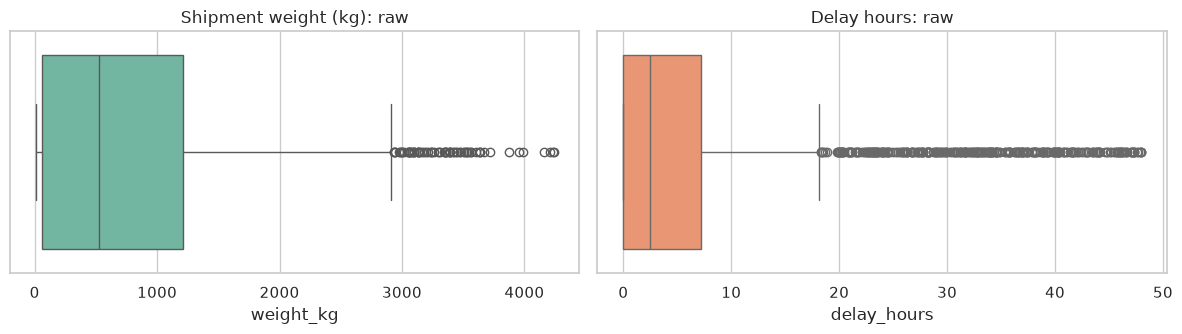

In [10]:
# Outliers (IQR rule) in the two continuous measures that carry outliers
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
sns.boxplot(x=raw["shipments"]["weight_kg"], ax=axes[0], color="#66c2a5").set_title("Shipment weight (kg): raw")
sns.boxplot(x=raw["deliveries"]["delay_hours"], ax=axes[1], color="#fc8d62").set_title("Delay hours: raw")
plt.tight_layout(); utils.save_fig(fig, "01_raw_outliers_boxplots"); plt.show()

In [11]:
cross = dc.cross_table_checks(raw)
cross

,check,violations,note
0,shipments.warehouse_id not in warehouses,0,FK integrity
1,shipments.driver_id not in drivers,0,FK integrity
2,shipments.vehicle_id not in vehicles,0,FK integrity
3,shipments.route_id not in routes,0,FK integrity
4,deliveries.shipment_id not in shipments,0,FK integrity
5,feedback.delivery_id not in deliveries,0,FK integrity
6,shipments with >1 delivery record,0,expected 1:1
7,deliveries with >1 feedback record,0,expected 1:1
8,actual_dt earlier than shipment_dt,0,impossible timeline
9,In-Transit/Cancelled rows that carry an actual_dt,288,not delivered yet / never delivered -> actual_...


### Data-quality findings
* **Completeness and uniqueness:** no missing values, no duplicate rows, and every primary key is unique in all 7 tables.
* **Referential integrity:** every foreign key resolves, and shipments, deliveries and feedback are strictly 1:1:1.
* **Types:** date columns are read as text, so they must be converted to DATE/DATETIME. `distance_km` is stored as an integer but documented as FLOAT.
* **Logical issues found:**
  * **288 In-Transit/Cancelled deliveries carry an `actual_dt` and `delay_hours = 0`.** These orders were never delivered, so the timestamp and the "0 hours delay" are not real. Left as they are, they would make the delay KPIs look better than they are.
  * **1,457 "Delivered" records have `delay_hours > 0`** (max ≈ 20 h). The status label treats small delays as Delivered. Following the brief, `is_delayed` is defined as `delay_hours > 0`, and the status column is kept for the success-rate KPI.
  * **252 shipments are dated before the assigned driver's `join_date`**, a driver-master inconsistency. The records are kept and flagged (`driver_join_conflict`), because nothing in the data shows which of the two dates is wrong.
  * 288 feedback rows belong to In-Transit/Cancelled orders. They are kept, since customers do rate cancelled or late orders.
* **Outliers:** `weight_kg` (73) and `delay_hours` (324) IQR outliers are real business variation (heavy truck loads, severe delays), so they are **kept** and analysed separately (Z-score test in Notebook 04).

## Step 5: Data Cleaning & Preprocessing
`src/data_cleaning.clean_all()` applies the same rule set to every table:
1. Normalise headers, trim whitespace and fix casing. Map category variants (for example `in transit` or `IN_TRANSIT`) to the canonical value.
2. Convert columns to their documented types (numeric, DATE, DATETIME). Unparsable values become NULL.
3. Remove exact duplicate rows and rows with a duplicate or missing primary key.
4. Set out-of-range numbers to NULL (rating outside 1-5, negative weight or delay), then impute them (median for numbers, mode for categories).
5. **Business rules:** for In-Transit/Cancelled deliveries, set `actual_dt` and `delay_hours` to NULL. Delivered-before-shipped timestamps become NULL.
6. Drop orphan foreign-key rows, cascading from parent to child tables.

In [12]:
cleaned, cleaning_log = dc.clean_all(raw)
cleaning_log

,table,action,rows_affected
0,deliveries,In-Transit/Cancelled: actual_dt set to NULL (n...,288
1,deliveries,In-Transit/Cancelled: delay_hours set to NULL ...,288


In [13]:
# Before vs after
compare = pd.DataFrame({
    "raw_rows": {t: len(raw[t]) for t in utils.TABLES},
    "clean_rows": {t: len(cleaned[t]) for t in utils.TABLES},
    "clean_nulls": {t: int(cleaned[t].isna().sum().sum()) for t in utils.TABLES},
})
display(compare)
print(cleaned["deliveries"].dtypes)
print(cleaned["deliveries"].groupby("status")[["actual_dt", "delay_hours"]].count())

,raw_rows,clean_rows,clean_nulls
warehouses,15,15,0
drivers,75,75,0
vehicles,45,45,0
routes,150,150,0
shipments,3000,3000,0
deliveries,3000,3000,576
feedback,3000,3000,0


delivery_id             int64
shipment_id             int64
actual_dt      datetime64[us]
status                 object
delay_hours           float64
dtype: object
            actual_dt  delay_hours
status                            
Cancelled           0            0
Delayed           480          480
Delivered        2232         2232
In-Transit          0            0


**Why NULLs remain in `deliveries`:** the 288 NULLs in `actual_dt` and `delay_hours` are intentional. A cancelled or pending order has no delivery time, and SQL `AVG()` skips NULLs, so the delay KPIs are computed only on completed deliveries.

### Robustness check: the pipeline on a deliberately corrupted copy
The official data is already fairly clean. To prove the cleaning rules work, we inject typical real-world problems into a **copy** (the real data is not changed) and re-run the pipeline.

In [14]:
rng = np.random.default_rng(42)
messy = {t: df.copy() for t, df in raw.items()}
s = messy["shipments"]
s.loc[rng.choice(s.index, 15, replace=False), "priority"] = " high "          # casing / whitespace
s.loc[rng.choice(s.index, 10, replace=False), "weight_kg"] = -5.0             # invalid weight
s.loc[rng.choice(s.index, 8, replace=False), "weight_kg"] = np.nan            # missing
messy["shipments"] = pd.concat([s, s.sample(12, random_state=1)])             # duplicates
d = messy["deliveries"]
d.loc[rng.choice(d.index, 10, replace=False), "status"] = "in transit"        # category variant
f = messy["feedback"]
f.loc[rng.choice(f.index, 6, replace=False), "rating"] = 9                    # out of range
messy["feedback"] = pd.concat([f, pd.DataFrame([{"feedback_id": 99999, "delivery_id": 77777, "rating": 4,
                                                 "comment": "orphan", "feedback_dt": "2025-01-01"}])])
_, messy_log = dc.clean_all(messy)
messy_log

,table,action,rows_affected
0,shipments,standardised text/casing in 'priority',16
1,shipments,removed exact duplicate rows,12
2,shipments,out-of-range 'weight_kg' set to NULL (valid 0....,10
3,deliveries,standardised text/casing in 'status',10
4,feedback,out-of-range 'rating' set to NULL (valid 1..5),6
5,deliveries,In-Transit/Cancelled: actual_dt set to NULL (n...,296
6,deliveries,In-Transit/Cancelled: delay_hours set to NULL ...,296
7,shipments,imputed missing 'weight_kg' with median,18
8,feedback,imputed missing 'rating' with median,6
9,feedback,dropped orphan rows (delivery_id not in delive...,1


## Step 6: Store Cleaned Data in SQL
* Cleaned CSVs are saved to `data/cleaned/`.
* `sql/schema.sql` creates the 7 tables with **PRIMARY KEY, FOREIGN KEY, NOT NULL and CHECK** constraints, plus indexes and the `vw_logitrack` analysis view.
* The connection comes from `utils.get_engine()` (SQLAlchemy). The DB URL is read from the `LOGITRACK_DB_URL` environment variable, so no credentials are hard-coded. The default is a local SQLite file, `data/logitrack.db`.
* Tables are loaded parents first (warehouses, drivers, vehicles, routes, then shipments, deliveries, feedback) so FK checks pass.

In [15]:
utils.CLEANED_DIR.mkdir(parents=True, exist_ok=True)
for t, df in cleaned.items():
    df.to_csv(utils.CLEANED_DIR / f"{t}_cleaned.csv", index=False)
sorted(p.name for p in utils.CLEANED_DIR.glob("*_cleaned.csv"))

['deliveries_cleaned.csv',
 'drivers_cleaned.csv',
 'feedback_cleaned.csv',
 'routes_cleaned.csv',
 'shipments_cleaned.csv',
 'vehicles_cleaned.csv',
 'warehouses_cleaned.csv']

In [16]:
engine = utils.get_engine()
print("Connected to:", engine.url.render_as_string(hide_password=True))
utils.create_schema(engine)                       # DROP + CREATE with PK/FK constraints
for t in utils.TABLES:                            # parents first
    n = utils.load_table(cleaned[t], t, engine)
    print(f"loaded {n:>5} rows into {t}")

Connected to: sqlite:////workspace/LogiTrack/data/logitrack.db
loaded    15 rows into warehouses
loaded    75 rows into drivers
loaded    45 rows into vehicles
loaded   150 rows into routes


loaded  3000 rows into shipments
loaded  3000 rows into deliveries


loaded  3000 rows into feedback


In [17]:
# Verify: row counts, FK integrity, constraints actually defined
report = utils.verify_database(engine)
report["rows_in_csv"] = [len(cleaned[t]) for t in report["table"]]
display(report)
print("Foreign-key violations:", report.attrs.get("fk_violations"))
display(utils.run_query("SELECT * FROM pragma_foreign_key_list('shipments')", engine=engine))

,table,rows_in_db,rows_in_csv
0,warehouses,15,15
1,drivers,75,75
2,vehicles,45,45
3,routes,150,150
4,shipments,3000,3000
5,deliveries,3000,3000
6,feedback,3000,3000


Foreign-key violations: 0


,id,seq,table,from,to,on_update,on_delete,match
0,0,0,routes,route_id,route_id,NO ACTION,NO ACTION,NONE
1,1,0,vehicles,vehicle_id,vehicle_id,NO ACTION,NO ACTION,NONE
2,2,0,drivers,driver_id,driver_id,NO ACTION,NO ACTION,NONE
3,3,0,warehouses,warehouse_id,warehouse_id,NO ACTION,NO ACTION,NONE


In [18]:
# Constraint test: inserting a shipment with a non-existent driver must fail
from sqlalchemy import text
try:
    with engine.begin() as conn:
        conn.execute(text("INSERT INTO shipments VALUES (999999, 1, 9999, 1, 1, '2025-01-01 10:00:00', 10, 'High')"))
    print("Unexpected: insert succeeded")
except Exception as e:
    print("FK constraint enforced ->", type(e).__name__, str(e).splitlines()[0])

FK constraint enforced -> IntegrityError (sqlite3.IntegrityError) FOREIGN KEY constraint failed


In [19]:
utils.run_query("""
SELECT d.status, COUNT(*) AS deliveries, ROUND(AVG(d.delay_hours), 2) AS avg_delay_h, ROUND(AVG(f.rating), 2) AS avg_rating
FROM deliveries d LEFT JOIN feedback f ON f.delivery_id = d.delivery_id
GROUP BY d.status ORDER BY deliveries DESC""", engine=engine)

,status,deliveries,avg_delay_h,avg_rating
0,Delivered,2232,3.14,4.35
1,Delayed,480,25.39,2.91
2,In-Transit,147,NaN,2.02
3,Cancelled,141,NaN,1.91


**Next:** `02_feature_engineering.ipynb` builds the shipment-level feature table and stores it in SQL (`shipment_features`).